In [1]:
import matplotlib.pyplot as plt

In [3]:
import pandas as pd

df = pd.read_excel("bitcoin market features table 10.xlxs.xlsx")

In [5]:
df[["trade_date", "close_price"]].head(10)

,trade_date,close_price
0,2015-10-13,249.507996
1,2016-05-31,531.385986
2,2020-06-22,9648.717773
3,2019-12-08,7564.345215
4,2020-02-11,10208.236330
5,2019-04-21,5314.531250
6,2022-08-14,24319.333980
7,2023-02-08,22939.398440
8,2024-06-02,67751.601560
9,2025-02-09,96500.093750


In [7]:
df["trade_date"] = pd.to_datetime(df["trade_date"])

In [11]:
df = df.sort_values("trade_date")

In [13]:
import numpy as np

In [15]:
df["recovery_status"] = np.where(
    df["drawdown_pct"] == 0,
    "Recovered",
    "In Drawdown"
)

df["recovery_status"].value_counts()

recovery_status
In Drawdown    3995
Recovered       189
Name: count, dtype: int64

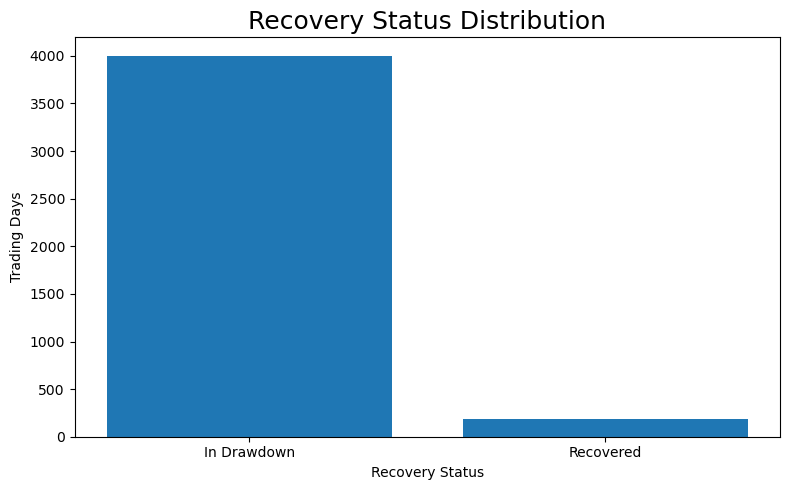

In [17]:
recovery_counts = df["recovery_status"].value_counts()

plt.figure(figsize=(8,5))

plt.bar(
    recovery_counts.index,
    recovery_counts.values
)

plt.title("Recovery Status Distribution", fontsize=18)

plt.xlabel("Recovery Status")

plt.ylabel("Trading Days")

plt.tight_layout()

plt.show()

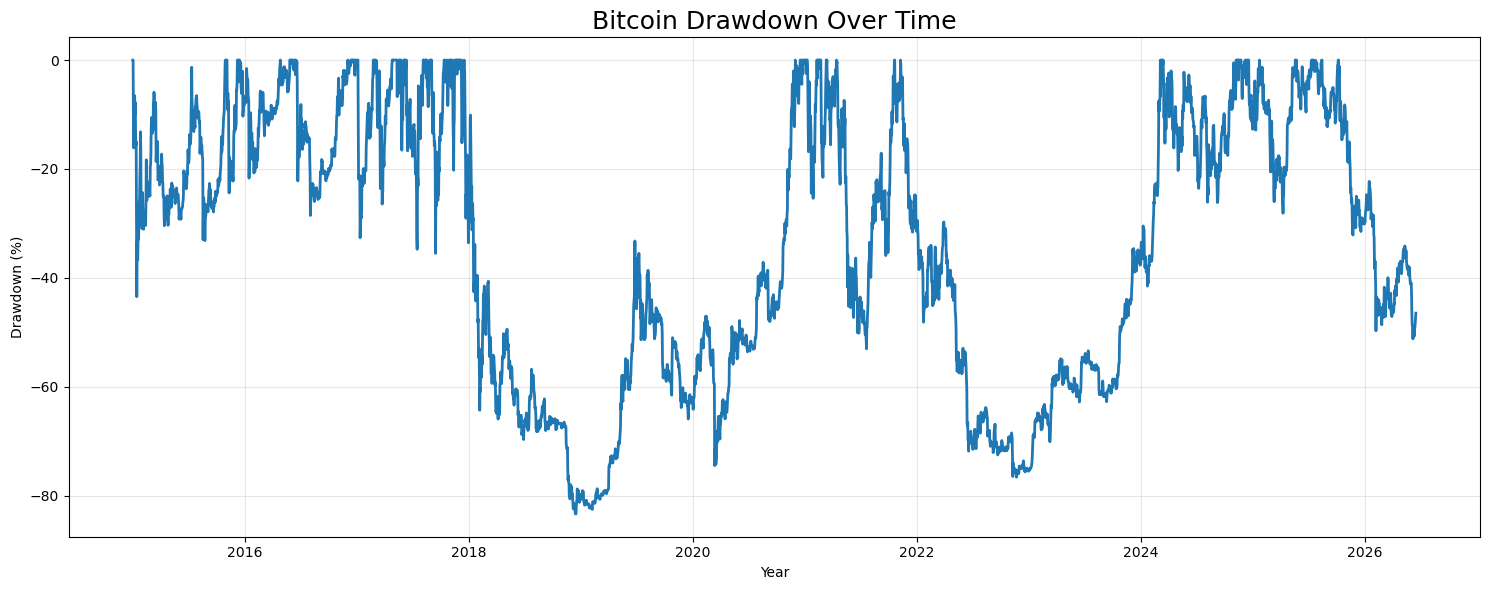

In [19]:
plt.figure(figsize=(15,6))

plt.plot(
    df["trade_date"],
    df["drawdown_pct"],
    linewidth=2
)

plt.title("Bitcoin Drawdown Over Time", fontsize=18)

plt.xlabel("Year")

plt.ylabel("Drawdown (%)")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

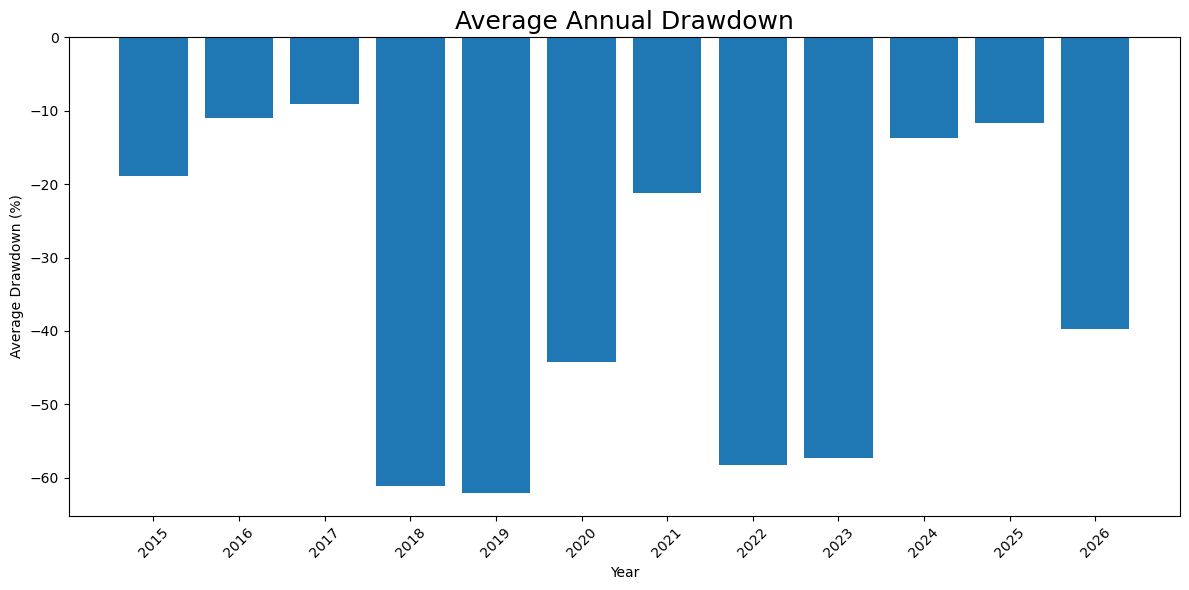

In [20]:
annual_drawdown = (
    df.groupby(df["trade_date"].dt.year)["drawdown_pct"]
      .mean()
)

plt.figure(figsize=(12,6))

plt.bar(
    annual_drawdown.index.astype(str),
    annual_drawdown.values
)

plt.title("Average Annual Drawdown", fontsize=18)

plt.xlabel("Year")

plt.ylabel("Average Drawdown (%)")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

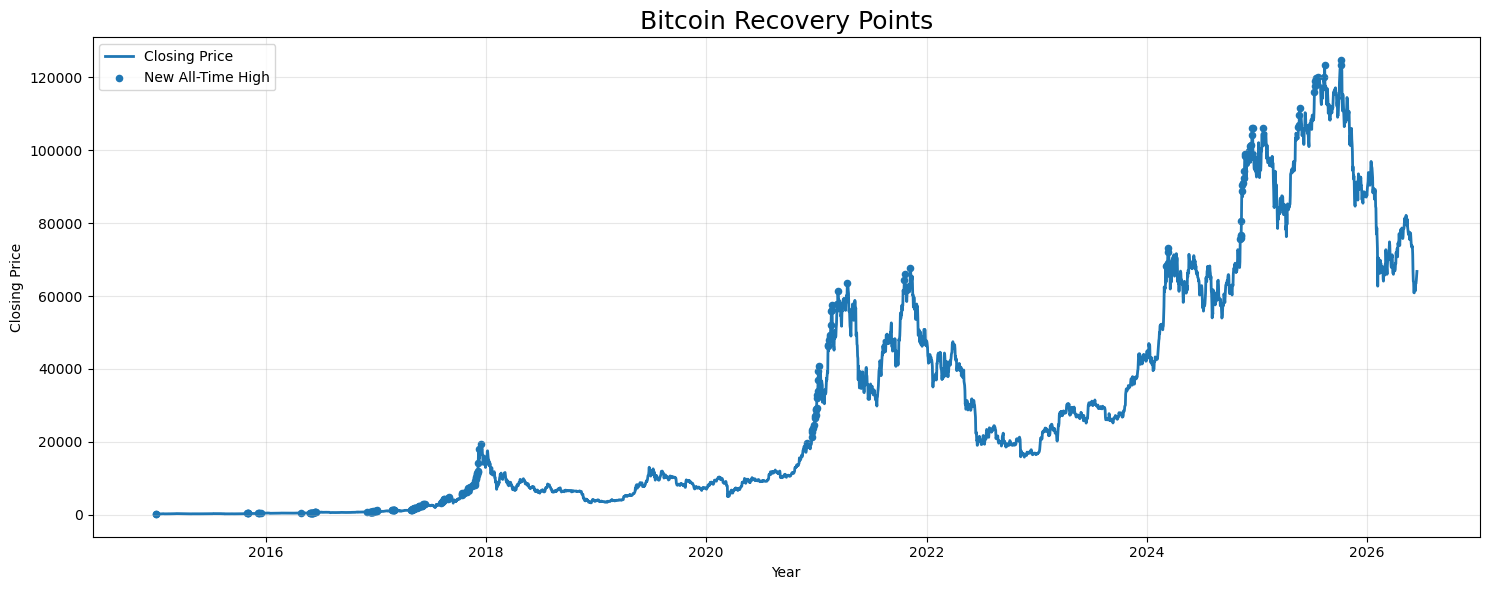

In [21]:
plt.figure(figsize=(15,6))

plt.plot(
    df["trade_date"],
    df["close_price"],
    label="Closing Price",
    linewidth=2
)

recovered = df[df["recovery_status"] == "Recovered"]

plt.scatter(
    recovered["trade_date"],
    recovered["close_price"],
    s=20,
    label="New All-Time High",
)

plt.title("Bitcoin Recovery Points", fontsize=18)

plt.xlabel("Year")

plt.ylabel("Closing Price")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()